# Fine-tune on PanopTILs Refined

Adapt a pretrained CellPose network to the breast tissue images and nucleus labels
from [PanopTILs Refined](https://huggingface.co/datasets/histolytics-hub/panoptils_refined).
An instance label identifies one nucleus; a class label gives its cell type.
We use images, nucleus instances and cell types only, never tissue-area masks.

This notebook starts with the
[HGSC weights](https://huggingface.co/csmp-hub/cellpose-histo-hgsc-nuc-v1)
(Apache 2.0) and the same patient-separated subset as the training notebook.
PanopTILs Refined is CC0-1.0; see its card for attribution.

It runs two epochs with the encoder frozen, then two with it unfrozen. An epoch
is one pass through the training data. You will save and reload the model and
optimizer, then view a held-out prediction. This tiny run teaches the workflow;
it does not establish segmentation quality.

A CUDA GPU is used when available, with CPU as the fallback.

## Prepare the data

Follow [the training notebook's preparation step](training.ipynb)
first. If you already prepared `data/panoptils`, reuse it rather than downloading again.
Open this notebook from `docs/tutorials/` with the same environment.

The subset has three training regions from two patients and one validation region
from another patient. Its 256 × 256 crops preserve the original pixel scale; images
and masks are cropped together, not resized. Keep patients separate in larger runs.

## Setup

In [1]:
import json
from pathlib import Path

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from skimage.color import label2rgb
from torch.utils.data import DataLoader

from cellseg_models_pytorch.models.cellpose import CellPose
from cellseg_models_pytorch.models.cellpose.cellpose_unet import cellpose_nuclei
from cellseg_models_pytorch.torch_datasets import TrainDatasetFolder
from cellseg_models_pytorch.transforms.albu_transforms import (
    ApplyEach,
    CellposeTransform,
    MinMaxNormalization,
)

# Fix the seed; GPU operations can still introduce small run-to-run differences.
torch.manual_seed(0)
torch.set_num_threads(2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_root = Path("../../data/panoptils")
print(f"Device: {device}")

Device: cuda


## Load images and targets

Use the same global min-max normalization as the pretrained checkpoint.
`CellposeTransform` creates flows pointing toward each nucleus's centre. These
flows and the cell-type labels are the two targets used below.

In [2]:
transforms = A.Compose([MinMaxNormalization(copy=True)])
instance_transforms = ApplyEach([CellposeTransform()], as_list=True)

train_dataset = TrainDatasetFolder(
    str(data_root / "train/images"),
    str(data_root / "train/labels"),
    mask_keys=("inst", "type"),
    transforms=transforms,
    inst_transforms=instance_transforms,
)
validation_dataset = TrainDatasetFolder(
    str(data_root / "validation/images"),
    str(data_root / "validation/labels"),
    mask_keys=("inst", "type"),
    transforms=transforms,
    inst_transforms=instance_transforms,
)

# Shuffle training examples; keep validation order fixed.
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, num_workers=0)
validation_loader = DataLoader(
    validation_dataset, batch_size=2, shuffle=False, num_workers=0
)
print(f"Regions: {len(train_dataset)} training, {len(validation_dataset)} validation")

Regions: 3 training, 1 validation


## Load weights and adapt the class output

Both datasets have seven classes, but their meanings differ. For example,
PanopTILs class 2 means stromal cells; HGSC class 2 means inflammatory cells.
Reinitialize the final class output layer rather than reuse those predictions.
Keep the pretrained encoder, decoder features and flow output layer.

PanopTILs IDs remain 0 background, 1 neoplastic, 2 stromal, 3 inflammatory,
4 epithelial, 5 other and 6 unknown. Do not renumber classes missing from this subset.
The first run downloads the pinned checkpoint; later runs reuse the cache.

In [3]:
checkpoint_path = Path(hf_hub_download(
    repo_id="csmp-hub/cellpose-histo-hgsc-nuc-v1",
    filename="cellpose_hgsc_v1_efficientnet_b5.safetensors",
    revision="88c7ffd3a9106d1673c3dd6e6a9e42476e8320d2",
))
model = CellPose.from_pretrained(checkpoint_path, device=device).model

class_names = [
    "background", "neoplastic", "stromal", "inflammatory",
    "epithelial", "other", "unknown",
]

# The datasets have different class meanings, so relearn the class output layer.
model.decoder["type-nuc_type_head"].head.reset_parameters()

encoder = model[model.enc_name]
for parameter in encoder.parameters():
    parameter.requires_grad_(False)

optimizer = torch.optim.Adam(
    (p for p in model.parameters() if p.requires_grad), lr=1e-4
)


## Train and validate one epoch

Cross entropy trains the cell classes. Mean squared error trains the flows.
These two functions reuse the same steps in both training phases. Validation
uses held-out patients without updating weights. Losses average over images.

In [4]:
def train_epoch(model, loader, optimizer):
    total = 0.0
    for batch in loader:
        images = batch["image"].to(device)
        class_targets = batch["type"].long().to(device)
        flow_targets = batch["cellpose_inst"].float().to(device)

        optimizer.zero_grad(set_to_none=True)
        prediction = model(images)["nuc"]
        loss = F.cross_entropy(prediction.type_map, class_targets)
        loss = loss + F.mse_loss(prediction.aux_map, flow_targets)
        loss.backward()
        optimizer.step()
        total += float(loss.detach()) * images.shape[0]

    return total / len(loader.dataset)


def validate_epoch(model, loader):
    total = 0.0
    with torch.inference_mode():
        for batch in loader:
            images = batch["image"].to(device)
            class_targets = batch["type"].long().to(device)
            flow_targets = batch["cellpose_inst"].float().to(device)

            output = model(images)["nuc"]
            loss = F.cross_entropy(output.type_map, class_targets)
            loss = loss + F.mse_loss(output.aux_map, flow_targets)
            total += float(loss) * images.shape[0]

    return total / len(loader.dataset)


## Train with the encoder frozen

Start by adapting the decoder and class output. Keep the encoder in evaluation
mode during training so its BatchNorm statistics stay frozen with its weights.

In [5]:
for epoch in range(2):
    model.train()
    # Keep the frozen encoder's BatchNorm statistics unchanged too.
    encoder.eval()
    training_loss = train_epoch(model, train_loader, optimizer)

    model.eval()
    validation_loss = validate_epoch(model, validation_loader)
    print(
        f"Frozen epoch {epoch + 1}: training loss {training_loss:.3f}, "
        f"validation loss {validation_loss:.3f}"
    )


Frozen epoch 1: training loss 1.734, validation loss 1.535


Frozen epoch 2: training loss 1.675, validation loss 1.509


## Unfreeze at a lower learning rate

Now allow the encoder to adapt too. The new optimizer deliberately starts fresh
history for this phase; that differs from resuming a saved run.

In [6]:
for parameter in encoder.parameters():
    parameter.requires_grad_(True)

# Start a new optimizer for this phase at a lower learning rate.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)

for epoch in range(2):
    model.train()
    training_loss = train_epoch(model, train_loader, optimizer)

    model.eval()
    validation_loss = validate_epoch(model, validation_loader)
    print(
        f"Unfrozen epoch {epoch + 1}: training loss {training_loss:.3f}, "
        f"validation loss {validation_loss:.3f}"
    )


Unfrozen epoch 1: training loss 1.597, validation loss 1.505


Unfrozen epoch 2: training loss 1.579, validation loss 1.512


## Save and reload

Choose a new filename before rerunning this cell. The checkpoint stores the
architecture, PanopTILs classes, data split, preprocessing, training phase, weights,
optimizer and Torch random states. This example uses no scheduler, mixed precision
or random augmentation; retain their state too if you introduce them.

This training checkpoint is loaded with the matching network and `load_state_dict`,
not `CellPose.from_pretrained`. Never load an unknown pickle with
`weights_only=False`.

In [7]:
# Choose a new filename on each run; "xb" protects an existing checkpoint.
saved_checkpoint = Path("finetuned-panoptils.pt")
with saved_checkpoint.open("xb") as destination:
    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "epoch": 4,
            "phase": "unfrozen",
            "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state(device) if device.type == "cuda" else None,
            "encoder": model.enc_name,
            "class_names": class_names,
            "normalization": "global min-max, RGB float32",
            "data_manifest": json.loads((data_root / "manifest.json").read_text()),
        },
        destination,
    )

# Load on CPU so random states remain CPU byte tensors; use restricted loading.
state = torch.load(saved_checkpoint, map_location="cpu", weights_only=True)
restored = cellpose_nuclei(
    len(state["class_names"]), enc_name=state["encoder"], enc_pretrain=False
).to(device)
restored.load_state_dict(state["model"], strict=True)

# Restore Adam's history as well as the network weights.
resumed_optimizer = torch.optim.Adam(restored.parameters(), lr=1e-5)
resumed_optimizer.load_state_dict(state["optimizer"])

# Restore random state after creating the new network.
torch.set_rng_state(state["torch_rng"])
if device.type == "cuda" and state["cuda_rng"] is not None:
    torch.cuda.set_rng_state(state["cuda_rng"], device)

print("Reloaded network and optimizer after epoch", state["epoch"])


Reloaded network and optimizer after epoch 4


## View a held-out prediction

The prediction comes from the reloaded model. Compare the tissue image and target
instances with predicted cell classes. These are dense class labels, not reconstructed
instances. Colours display label numbers. Use more patients and evaluate reconstructed
instances before treating a longer run as a useful segmentation model.

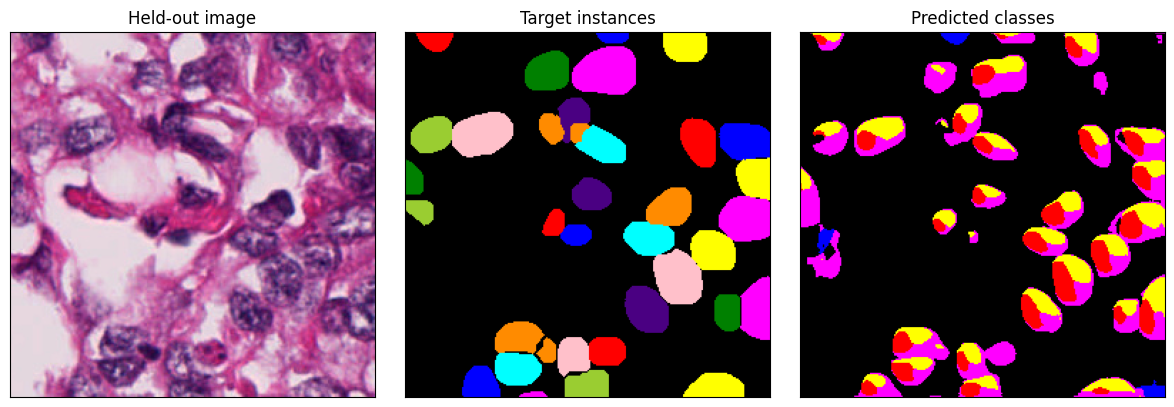

In [8]:
example = validation_dataset[0]
restored.eval()
with torch.inference_mode():
    output = restored(example["image"].unsqueeze(0).to(device))["nuc"]

# Move only the displayed maps to CPU for plotting.
# Keep display pixels in the RGB range after floating-point normalization.
image = example["image"].permute(1, 2, 0).numpy().clip(0, 1)
instances = example["inst"].long().numpy()
predicted_classes = output.type_map.argmax(dim=1)[0].cpu().numpy()
instance_colors = label2rgb(instances, bg_label=0)
class_colors = label2rgb(predicted_classes, bg_label=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set(title="Held-out image", xticks=[], yticks=[])

axes[1].imshow(instance_colors)
axes[1].set(title="Target instances", xticks=[], yticks=[])

axes[2].imshow(class_colors)
axes[2].set(title="Predicted classes", xticks=[], yticks=[])

fig.tight_layout()
plt.show()